In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from IPython.core.pylabtools import figsize

In [2]:
df = pd.read_csv("train.csv")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
df_dropped = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

In [5]:
df_dropped

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S
887,1,1,female,19.0,0,0,30.0000,S
888,0,3,female,NaN,1,2,23.4500,S
889,1,1,male,26.0,0,0,30.0000,C


In [6]:
df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"], inplace=True)
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S
887,1,1,female,19.0,0,0,30.0000,S
888,0,3,female,NaN,1,2,23.4500,S
889,1,1,male,26.0,0,0,30.0000,C


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    str    
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(2)
memory usage: 55.8 KB


In [8]:
df.isna().sum()

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

In [9]:
df.isnull().sum()

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

In [10]:
df["Age"].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [11]:
df["Age"].unique()

array([22.  , 38.  , 26.  , 35.  ,   nan, 54.  ,  2.  , 27.  , 14.  ,
        4.  , 58.  , 20.  , 39.  , 55.  , 31.  , 34.  , 15.  , 28.  ,
        8.  , 19.  , 40.  , 66.  , 42.  , 21.  , 18.  ,  3.  ,  7.  ,
       49.  , 29.  , 65.  , 28.5 ,  5.  , 11.  , 45.  , 17.  , 32.  ,
       16.  , 25.  ,  0.83, 30.  , 33.  , 23.  , 24.  , 46.  , 59.  ,
       71.  , 37.  , 47.  , 14.5 , 70.5 , 32.5 , 12.  ,  9.  , 36.5 ,
       51.  , 55.5 , 40.5 , 44.  ,  1.  , 61.  , 56.  , 50.  , 36.  ,
       45.5 , 20.5 , 62.  , 41.  , 52.  , 63.  , 23.5 ,  0.92, 43.  ,
       60.  , 10.  , 64.  , 13.  , 48.  ,  0.75, 53.  , 57.  , 80.  ,
       70.  , 24.5 ,  6.  ,  0.67, 30.5 ,  0.42, 34.5 , 74.  ])

Text(0, 0.5, 'Count of Passengers')

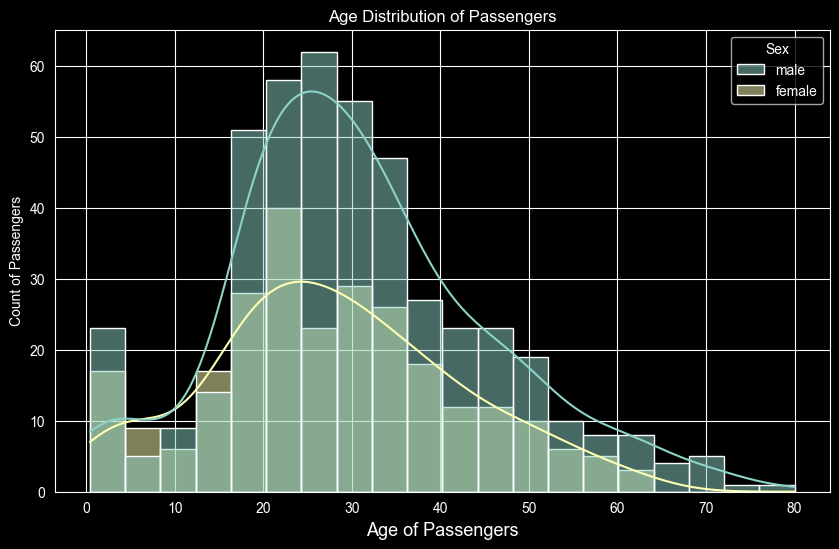

In [12]:
plt.figure(figsize=(10,6))
sns.histplot(data=df, x="Age", kde=True, hue="Sex")
plt.title("Age Distribution of Passengers")
plt.xlabel("Age of Passengers", fontsize=13)
plt.ylabel("Count of Passengers")

In [13]:
df_wrong = df.copy()
df_wrong

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S
887,1,1,female,19.0,0,0,30.0000,S
888,0,3,female,NaN,1,2,23.4500,S
889,1,1,male,26.0,0,0,30.0000,C


In [14]:
df_wrong["Age"] = df_wrong["Age"].fillna(df_wrong["Age"].median())
df_wrong["Age"].isna().sum()

np.int64(0)

<Axes: xlabel='Age', ylabel='Count'>

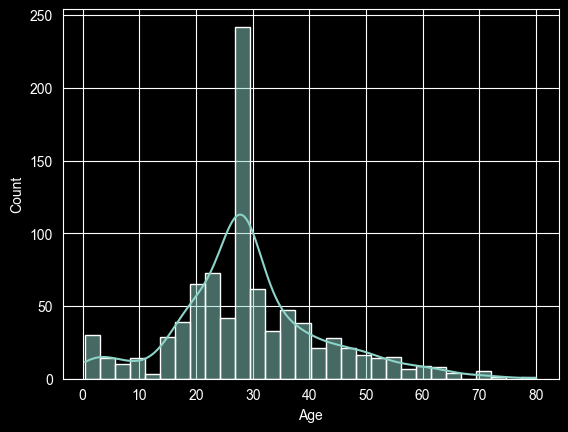

In [15]:
sns.histplot(data=df_wrong, x="Age", kde=True)

In [16]:
age_mean = df["Age"].mean()
age_std = df["Age"].std()

print(age_std, age_mean)

14.526497332334042 29.69911764705882


In [17]:
null_values = df["Age"].isnull().sum()
null_values

np.int64(177)

In [18]:
random_ages = np.random.randint(age_mean - age_std, age_mean + age_std + 1, null_values)
random_ages

array([44, 30, 19, 34, 28, 29, 32, 27, 44, 27, 21, 30, 19, 28, 41, 32, 35,
       23, 34, 44, 15, 30, 33, 44, 21, 18, 21, 42, 17, 32, 41, 17, 40, 23,
       41, 29, 30, 28, 36, 27, 17, 42, 37, 21, 44, 30, 28, 26, 36, 42, 41,
       43, 22, 33, 38, 29, 43, 21, 16, 33, 44, 24, 43, 21, 17, 31, 37, 22,
       39, 23, 28, 23, 37, 36, 21, 34, 23, 17, 19, 23, 25, 16, 36, 43, 38,
       32, 37, 28, 36, 15, 32, 34, 16, 18, 40, 19, 30, 22, 42, 41, 35, 20,
       25, 19, 43, 40, 36, 43, 26, 24, 39, 38, 28, 25, 41, 27, 23, 22, 23,
       40, 19, 15, 18, 38, 33, 19, 25, 22, 26, 27, 26, 30, 31, 16, 36, 27,
       16, 23, 17, 37, 31, 16, 21, 35, 43, 22, 23, 22, 31, 22, 21, 21, 43,
       24, 22, 34, 21, 32, 42, 33, 18, 39, 34, 37, 31, 36, 30, 26, 44, 22,
       27, 34, 42, 18, 17, 31, 36])

In [19]:
df.loc[df["Age"].isnull(), "Age"] = random_ages

In [20]:
df["Age"].isnull().sum()

np.int64(0)

<Axes: xlabel='Age', ylabel='Count'>

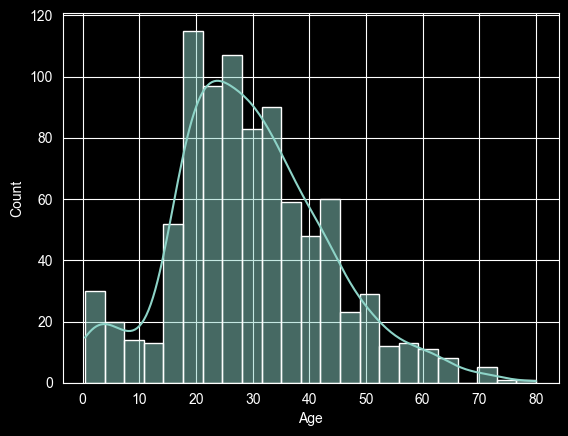

In [21]:
sns.histplot(data=df, x="Age", kde=True)

In [22]:
df.isnull().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    2
dtype: int64

In [23]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [24]:
mode = df["Embarked"].mode()
type(mode)

pandas.Series

In [25]:
mode[0]

'S'

In [26]:
df.isnull().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

<Axes: xlabel='Embarked', ylabel='percent'>

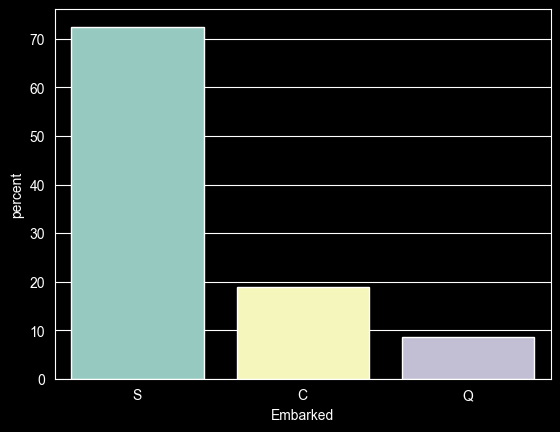

In [27]:
sns.countplot(data=df, x="Embarked", hue="Embarked", stat="percent")

In [28]:
df["Embarked"].value_counts()

Embarked
S    646
C    168
Q     77
Name: count, dtype: int64

In [29]:
df["Pclass"].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

<Axes: xlabel='Pclass', ylabel='percent'>

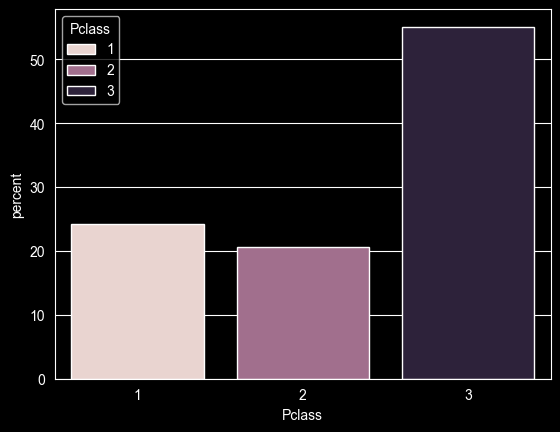

In [30]:
sns.countplot(data=df, x="Pclass", hue="Pclass", stat="percent")

In [31]:
survival_rates = df.groupby("Pclass")["Survived"].mean()
survival_rates

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [32]:
death_rates = (1 - survival_rates) * 100
death_rates

Pclass
1    37.037037
2    52.717391
3    75.763747
Name: Survived, dtype: float64

In [37]:
type(death_rates)

pandas.Series

In [33]:
death_rates_df = death_rates.reset_index()

In [38]:
death_rates_df

,Pclass,Survived
0,1,37.037037
1,2,52.717391
2,3,75.763747


<Axes: xlabel='Pclass', ylabel='Survived'>

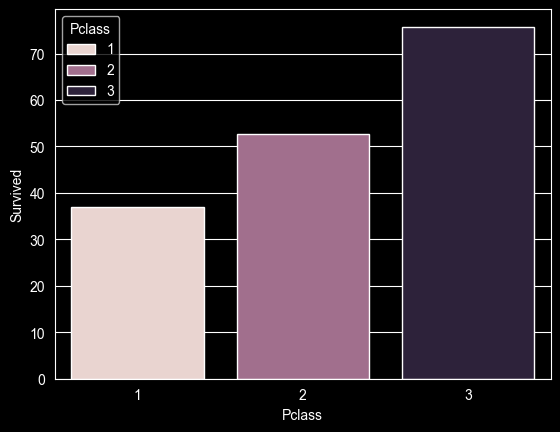

In [40]:
sns.barplot(data=death_rates_df, x="Pclass", y = "Survived", hue="Pclass")

In [42]:
df.groupby(["Pclass", "Sex"])["Survived"].mean()

Pclass  Sex   
1       female    0.968085
        male      0.368852
2       female    0.921053
        male      0.157407
3       female    0.500000
        male      0.135447
Name: Survived, dtype: float64

In [45]:
death_gender = (1 -  df.groupby(["Pclass", "Sex"])["Survived"].mean()) * 100
print(death_gender)
type(death_gender)

Pclass  Sex   
1       female     3.191489
        male      63.114754
2       female     7.894737
        male      84.259259
3       female    50.000000
        male      86.455331
Name: Survived, dtype: float64


pandas.Series

In [46]:
death_gender_df = death_gender.reset_index()

In [48]:
death_gender_df.rename(columns={'Survived': "Death Rate"}, inplace=True)

In [49]:
death_gender_df

,Pclass,Sex,Death Rate
0,1,female,3.191489
1,1,male,63.114754
2,2,female,7.894737
3,2,male,84.259259
4,3,female,50.000000
5,3,male,86.455331


Text(0, 0.5, 'Death Rate')

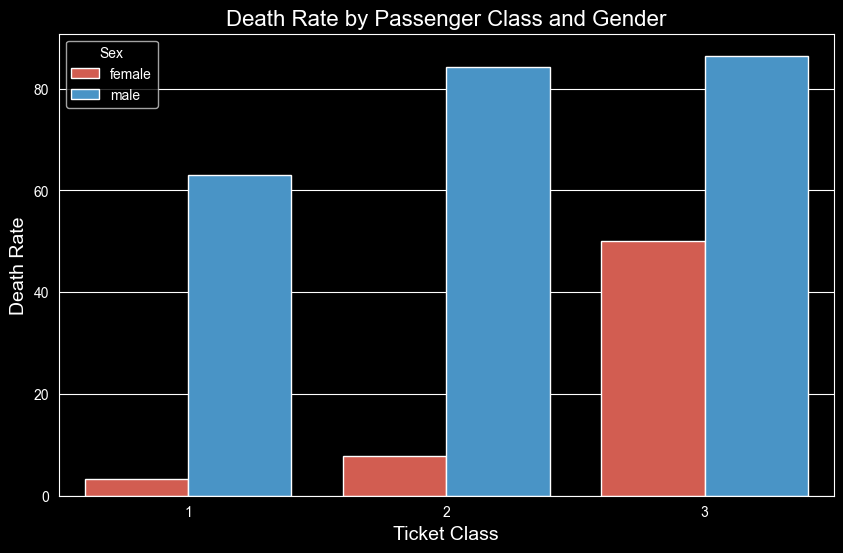

In [57]:
plt.figure(figsize=(10,6))
sns.barplot(data=death_gender_df,
            x="Pclass",
            y="Death Rate",
            hue="Sex",
            palette={'male': '#3498db', 'female': '#e74c3c'})
plt.title("Death Rate by Passenger Class and Gender", fontsize=16)
plt.xlabel("Ticket Class", fontsize=14)
plt.ylabel("Death Rate", fontsize=14)

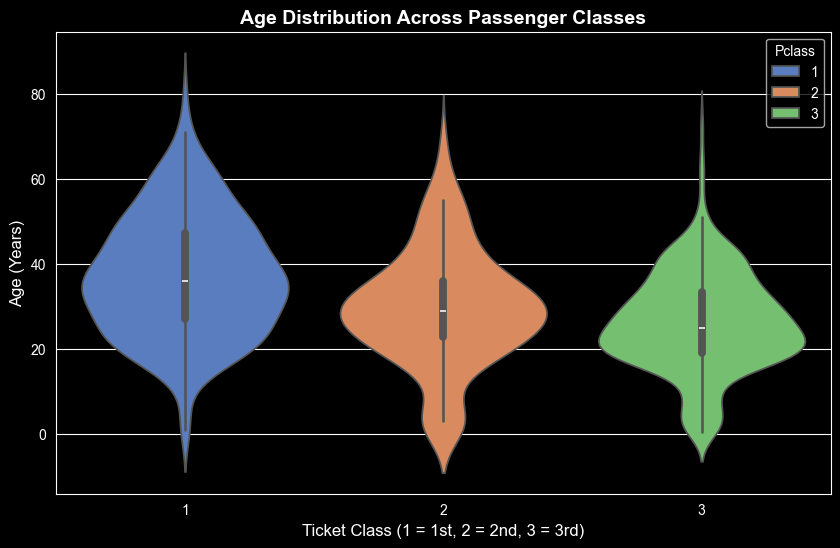

In [61]:
plt.figure(figsize=(10, 6))

# A violin plot requires a categorical x-axis (Pclass) and a numerical y-axis (Age)
sns.violinplot(data=df, x='Pclass', y='Age', hue='Pclass', palette='muted')

plt.title('Age Distribution Across Passenger Classes', fontsize=14, fontweight='bold')
plt.xlabel('Ticket Class (1 = 1st, 2 = 2nd, 3 = 3rd)', fontsize=12)
plt.ylabel('Age (Years)', fontsize=12)

plt.show()

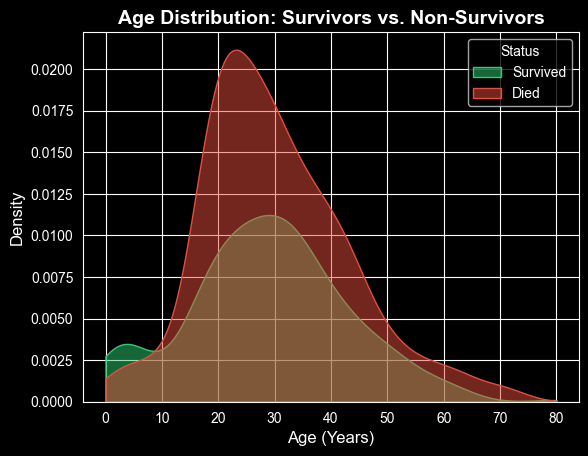

In [63]:
sns.kdeplot(
    data=df,
    x='Age',
    hue='Survived',
    fill=True,
    palette={0: '#e74c3c', 1: '#2ecc71'},
    alpha=0.5,
    clip=(0, 80) # <--- This is the magic fix! It builds a wall at zero.
)

plt.title('Age Distribution: Survivors vs. Non-Survivors', fontsize=14, fontweight='bold')
plt.xlabel('Age (Years)', fontsize=12)
plt.ylabel('Density', fontsize=12)

plt.legend(title='Status', labels=['Survived', 'Died'])

In [64]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64